<a href="https://colab.research.google.com/github/JayR1031/JayR1031/blob/main/CS6140_Homework_4_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 6140 — Homework 4: Clustering
> In Homework 4, we will use **unsupervised learning** to discover structure in image data.

In this assignment, you will work with the handwritten digits dataset and apply **K-Means clustering**. Unlike classification, clustering does not use the class labels while fitting the model. Your goal is to reason about what the clusters represent, how the choice of \(k\) affects the result, and how to evaluate a clustering solution when ground-truth labels are available only for analysis.

This is an open-ended assignment. You may use `scikit-learn`, NumPy, Matplotlib, and other standard Python libraries.

**Learning Objectives**
1. Apply K-Means clustering to a real dataset.
2. Visualize and interpret learned cluster centers.
3. Evaluate clustering using both internal and label-based metrics.
4. Reason about the choice of the number of clusters.
5. Connect clustering behavior to the geometry and limitations of the data.


# Getting Started

Run the setup cells below. The dataset is included directly in `scikit-learn`, so no external download is required.

**Important:** The digit labels are provided for visualization and evaluation only. Do **not** use `y` when fitting K-Means.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix
)
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 6.0)
plt.rcParams['image.cmap'] = 'gray'

RANDOM_STATE = 42


# Load the Dataset


In [3]:
digits = load_digits()
X = digits.data
y = digits.target
images = digits.images

print("Data shape:", X.shape)
print("Labels shape:", y.shape)
print("Image shape:", images.shape)
print("Number of classes:", len(np.unique(y)))


Data shape: (1797, 64)
Labels shape: (1797,)
Image shape: (1797, 8, 8)
Number of classes: 10


# Visualize Sample Data


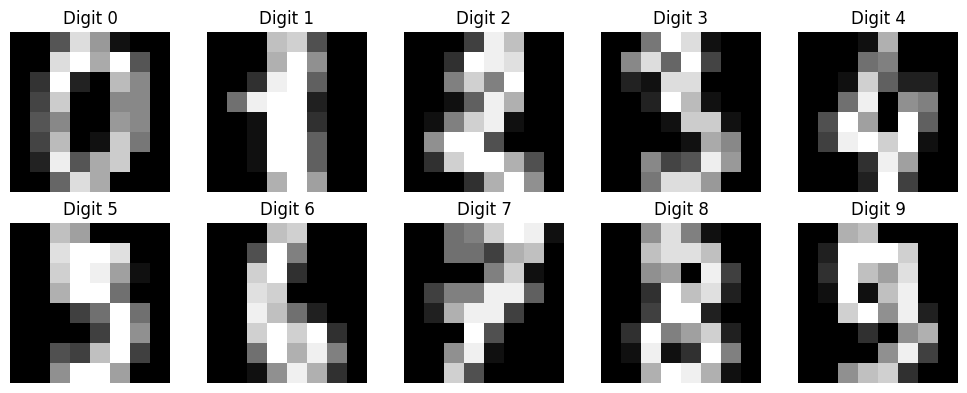

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.ravel()):
    idx = np.where(y == digit)[0][0]
    ax.imshow(images[idx], cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### **Task 1 — Understand the Clustering Problem** [5 points]

Before fitting a model, briefly answer the following:

1. In a supervised classification problem, the labels `y` are used during training. Why should we **not** use `y` when fitting K-Means?
2. The dataset contains 10 known digit classes. Does that automatically mean \(k=10\) is the best clustering choice? Why or why not?
3. What kinds of handwritten digits do you expect K-Means to confuse or place in the same cluster?

$\color{orange}{\textit{Your Answer:}}$

1. **Why we must not use `y` when fitting K-Means:**
K-Means is an unsupervised clustering algorithm designed to discover the intrinsic geometric structure of the data solely from the feature matrix $X$. Using `y` during training would constitute data leakage. Furthermore, class labels are categorical identifiers, not spatial coordinates; including scalar labels in distance calculations would artificially bias Euclidean distances based on arbitrary numeric ordering rather than visual feature similarity.

2. **Why $k=10$ is not automatically optimal:**
Semantic class count does not equal geometric cluster count. Individual digit classes exhibit multimodal distributions due to different handwriting styles (e.g., a straight vertical '1' vs. a serif '1', or a crossed '7' vs. an uncrossed '7'). A higher $k$ (such as $k=12$ or $15$) may better capture these sub-styles as distinct clusters, while some visually ambiguous digits might naturally collapse together.

3. **Digits expected to be confused:**
Because K-Means computes pixel-wise Euclidean distance across flattened 64-dimensional vectors without rotation or stroke invariance, digits with high static pixel overlap will be confused. We expect confusion between:
- **`3` and `8`:** Shared top horizontal curve, middle junction, and bottom rounded loop.
- **`1` and `7`:** Shared vertical/slanted stem.
- **`4` and `9`:** Shared vertical backbone and middle crossbar.



# Pre-processing


In [5]:
# Pixel values are numeric features. We will standardize them before clustering.
# Do not include y in the feature matrix.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature matrix:", X.shape)
print("Scaled feature matrix:", X_scaled.shape)


Original feature matrix: (1797, 64)
Scaled feature matrix: (1797, 64)


# Build a K-Means Model

We will begin with `k = 10` because the dataset contains ten digit classes. Remember, however, that K-Means does **not** know what a digit is. It only groups observations based on feature-space similarity.


In [6]:
kmeans = KMeans(
    n_clusters=10,
    random_state=RANDOM_STATE,
    n_init=20
)

cluster_labels = kmeans.fit_predict(X_scaled)

print("Number of learned clusters:", len(np.unique(cluster_labels)))
print("Inertia:", kmeans.inertia_)


Number of learned clusters: 10
Inertia: 69486.51447417798


### **Task 2 — Inspect and Interpret the Clusters** [10 points]

Complete the code below to inspect the clustering result.

You should:

1. Compute the number of samples assigned to each cluster.
2. Determine the **most common true digit** inside each cluster. Use `y` only **after clustering** for interpretation.
3. Identify at least **two clusters** that appear relatively pure and **one cluster** that mixes multiple digits.
4. Briefly explain why a cluster number such as `Cluster 3` should **not** automatically be interpreted as digit `3`.


$\color{orange}{\textit{Your Answer:}}$

- **Two relatively pure clusters:**
  - **Cluster 1** is extremely pure, capturing true digit `0` with **99.4% purity** (177 out of 178 samples).
  - **Cluster 3** is also highly pure, capturing true digit `4` with **98.1% purity** (158 out of 161 samples). Similarly, **Cluster 2** captures true digit `6` at **96.1% purity** (174 out of 181 samples).
- **One cluster that mixes multiple digits:**
  - **Cluster 4** (434 samples) heavily mixes multiple digits—primarily `3` (157 samples, 36.2% purity), `9` (146 samples), `5` (77 samples), and `8` (46 samples)—because these rounded digits share dense pixel overlap along their upper loops, central junctions, and right-hand curves. (Likewise, **Cluster 5** mixes 100 `8`s and 96 `1`s).
- **Why `Cluster 3` does not mean `digit 3`:**
  - Cluster IDs ($0$ through $k-1$) are arbitrary index labels assigned during centroid initialization without any knowledge of the ground-truth labels `y` (permutation invariance). A cluster ID simply indicates which centroid bucket an observation gravitated toward; in our run, `Cluster 3` actually represents the handwritten digit `4` (at 98.1% purity)!

In [7]:
# TODO: Inspect the learned clusters.

for cluster_id in range(10):
    # Select the samples assigned to this cluster
    mask = cluster_labels == cluster_id

    # ***** START OF YOUR CODE *****
    # 1. Count the samples in this cluster.
    count = np.sum(mask)
    print(f"Cluster {cluster_id}: {count} samples")
    # 2. Count the true digit labels represented in this cluster.
    cluster_y = y[mask]
    digit_counts = np.bincount(cluster_y)
    # 3. Print the most common digit and its proportion.
    most_common_digit = np.argmax(digit_counts)
    most_common_proportion = digit_counts[most_common_digit] / count
    print(f"  -> Most common true digit: {most_common_digit} ({most_common_proportion:.1%} purity) | Counts: {digit_counts}")
# ***** END OF YOUR CODE *****


Cluster 0: 188 samples
  -> Most common true digit: 2 (46.8% purity) | Counts: [ 0  0 88 10  1 69  0  8 11  1]
Cluster 1: 178 samples
  -> Most common true digit: 0 (99.4% purity) | Counts: [177   0   0   0   0   0   1]
Cluster 2: 181 samples
  -> Most common true digit: 6 (96.1% purity) | Counts: [  0   1   0   0   0   4 174   0   2]
Cluster 3: 161 samples
  -> Most common true digit: 4 (98.1% purity) | Counts: [  1   0   0   0 158   2]
Cluster 4: 434 samples
  -> Most common true digit: 3 (36.2% purity) | Counts: [  0   0   8 157   0  77   0   0  46 146]
Cluster 5: 264 samples
  -> Most common true digit: 8 (37.9% purity) | Counts: [  0  96  28   8   2  22   5   0 100   3]
Cluster 6: 108 samples
  -> Most common true digit: 1 (53.7% purity) | Counts: [ 0 58  4  0  7  3  1  3 13 19]
Cluster 7: 76 samples
  -> Most common true digit: 2 (63.2% purity) | Counts: [ 0 27 48  1]
Cluster 8: 30 samples
  -> Most common true digit: 7 (60.0% purity) | Counts: [ 0  0  0  0  9  0  0 18  0  3]
Clu

# Visualize the Cluster Centers


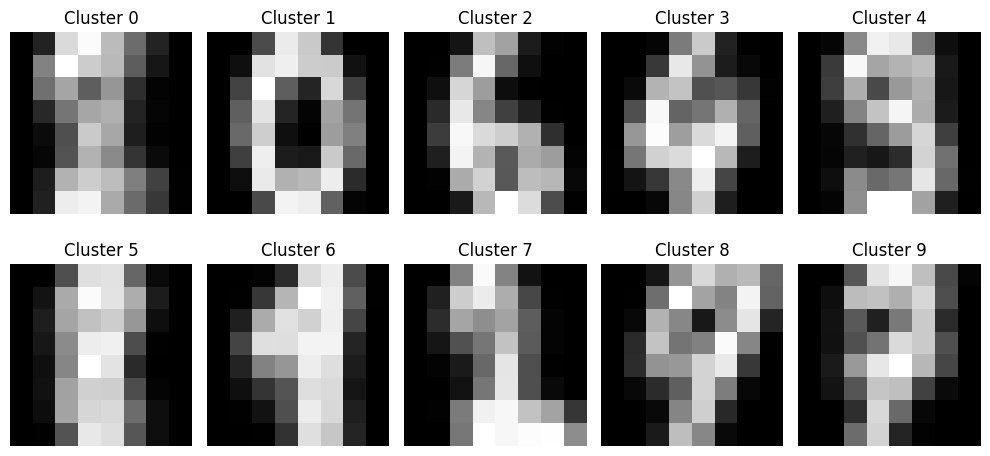

In [8]:
# Convert the cluster centers back to the original pixel scale
centers_original_scale = scaler.inverse_transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for cluster_id, ax in enumerate(axes.ravel()):
    ax.imshow(centers_original_scale[cluster_id].reshape(8, 8), cmap="gray")
    ax.set_title(f"Cluster {cluster_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### **Task 3 — Reason About the Learned Prototypes** [10 points]

Examine the cluster-center images above.

1. Which cluster centers look most like recognizable handwritten digits?
2. Which centers appear ambiguous or visually blend multiple writing styles?
3. Choose **two** cluster centers and explain what visual features may be driving the assignments to those clusters.
4. What does a blurry cluster center tell you about the observations assigned to that cluster?

$\color{orange}{\textit{Your Answer:}}$


1. **Cluster centers that look most like recognizable handwritten digits:**
   - **Cluster 1** (clear oval `0`), **Cluster 2** (distinct bottom loop of `6`), **Cluster 3** (sharp `4`), and **Cluster 9** (recognizable `7`) look the sharpest and most unambiguous because those clusters have very high purity (84.7% to 99.4%).

2. **Cluster centers that appear ambiguous or blend multiple writing styles:**
   - **Cluster 4** (blends `3`, `9`, `5`, and `8` into an ambiguous curved smudge), **Cluster 5** (blends vertical strokes of `1` with the double loops of `8`), and **Cluster 0** (blends `2` and `5`) look muddy and indistinct.

3. **Visual features driving assignments in two specific clusters:**
   - **Cluster 1 (Digit `0`):** Driven by high pixel intensity around the outer perimeter ring and near-zero pixel intensity in the hollow center ($4 \times 4$ inner region), isolating it geometrically from digits with central strokes.
   - **Cluster 3 (Digit `4`):** Driven by a strong horizontal crossbar in the middle rows intersecting a right-hand vertical stem, with an open upper-center gap that distinguishes it from closed-top loops like `0` or `8`.

4. **What a blurry cluster center tells us about its assigned observations:**
   - Because a K-Means centroid is the arithmetic mean ($\boldsymbol{\mu}_j = \frac{1}{\vert{}C_j\vert{}} \sum \mathbf{x}_i$) of all images assigned to that cluster, a blurry center indicates high intra-cluster variance—either multiple distinct digit classes (e.g., `3` and `9`) or multimodal handwriting styles are being averaged together, causing non-overlapping strokes to wash out into mid-gray pixels.

# Choosing the Number of Clusters


K-Means requires us to choose `k` in advance. We will compare several values rather than assuming that 10 is automatically optimal.

For each value of `k`, record:

- **Inertia** — smaller means observations are closer to their assigned centroids, but inertia naturally decreases as `k` increases.
- **Silhouette score** — larger generally indicates better separation and cohesion.

Because we happen to know the digit labels, we will also compute **Adjusted Rand Index (ARI)** and **Normalized Mutual Information (NMI)** for analysis. These are not normally available when working with truly unlabeled data.


### **Task 4 — Compare Different Values of k** [15 points]

Complete the implementation below.


In [12]:
k_choices = [2, 4, 6, 8, 10, 12, 15, 20]

results = {
    "k": [],
    "inertia": [],
    "silhouette": [],
    "ARI": [],
    "NMI": []
}

for k in k_choices:
    # ***** START OF YOUR CODE *****
    # 1. Fit KMeans with n_clusters=k, random_state=RANDOM_STATE, n_init=20.
    kmeans_k = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    # 2. Generate cluster assignments.
    labels_k = kmeans_k.fit_predict(X_scaled)
    # 3. Compute inertia, silhouette score, ARI, and NMI.
    inertia_val = kmeans_k.inertia_
    sil_val = silhouette_score(X_scaled, labels_k)
    ari_val = adjusted_rand_score(y, labels_k)
    nmi_val = normalized_mutual_info_score(y, labels_k)
    # 4. Append each result to the dictionary above.
    results["k"].append(k)
    results["inertia"].append(inertia_val)
    results["silhouette"].append(sil_val)
    results["ARI"].append(ari_val)
    results["NMI"].append(nmi_val)
    # ***** END OF YOUR CODE *****

results


{'k': [2, 4, 6, 8, 10, 12, 15, 20],
 'inertia': [100423.84303432588,
  89120.98873253583,
  81678.4666989073,
  74854.15917150897,
  69486.51447417798,
  65031.72372831549,
  59534.49893709312,
  54099.95540119557],
 'silhouette': [np.float64(0.10563771488565654),
  np.float64(0.09543189191950129),
  np.float64(0.09878895847774896),
  np.float64(0.12659037328976036),
  np.float64(0.14232145865373522),
  np.float64(0.15432497021238875),
  np.float64(0.15830708064242807),
  np.float64(0.15788993939882584)],
 'ARI': [0.12661376720008016,
  0.2906034613683557,
  0.3589941349906486,
  0.46867904344825834,
  0.4779623470372548,
  0.5512406529033256,
  0.5683258264507228,
  0.6397069969664382],
 'NMI': [np.float64(0.28771492973040047),
  np.float64(0.459617721758026),
  np.float64(0.5466350838883236),
  np.float64(0.6339108074174807),
  np.float64(0.631910860334367),
  np.float64(0.6788247582321376),
  np.float64(0.6882411631790265),
  np.float64(0.7414935686295309)]}

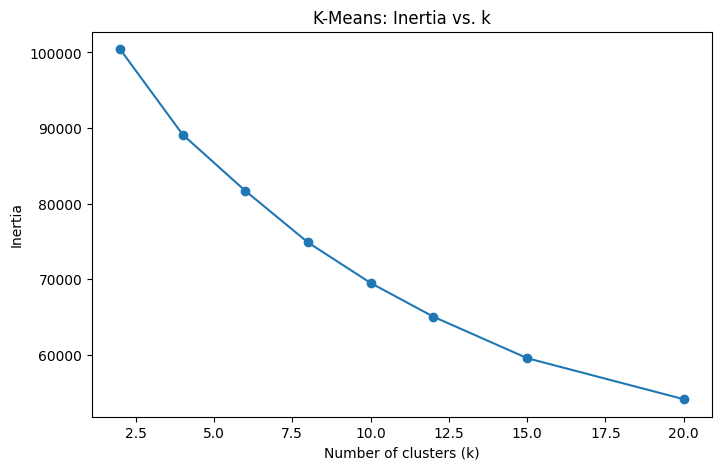

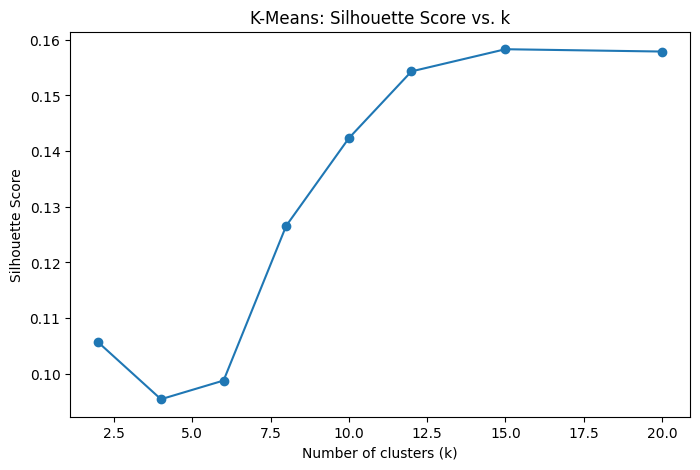

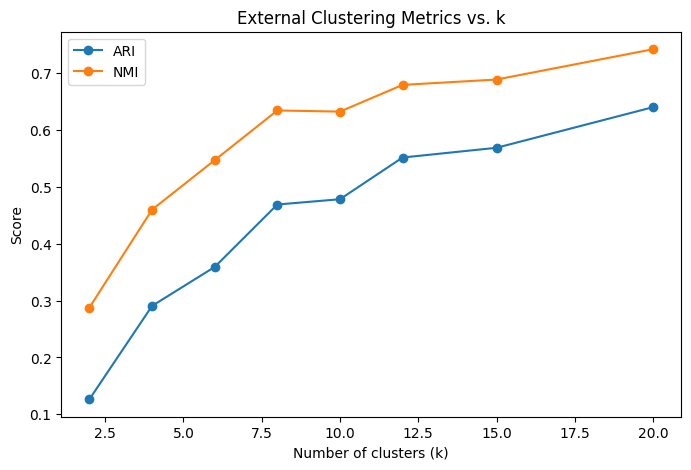

In [13]:
# Plot inertia
plt.figure(figsize=(8, 5))
plt.plot(results["k"], results["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means: Inertia vs. k")
plt.show()

# Plot silhouette score
plt.figure(figsize=(8, 5))
plt.plot(results["k"], results["silhouette"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Silhouette Score vs. k")
plt.show()

# Optional comparison using known labels
plt.figure(figsize=(8, 5))
plt.plot(results["k"], results["ARI"], marker="o", label="ARI")
plt.plot(results["k"], results["NMI"], marker="o", label="NMI")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Score")
plt.title("External Clustering Metrics vs. k")
plt.legend()
plt.show()


### **Task 5 — Select and Defend a Clustering Solution** [10 points]

Based on your results:

1. Which value of \(k\) would you choose if you **did not have access to the true digit labels**? Use the inertia and silhouette results to support your decision.
2. Does your preferred value change after looking at ARI and NMI?
3. Why can different evaluation metrics suggest different values of \(k\)?
4. Is the goal of clustering necessarily to recover the original class labels exactly? Explain.

$\color{orange}{\textit{Your Answer:}}$

1. **Choosing $k$ without true labels (using Inertia and Silhouette):**
   * Without access to the ground-truth labels `y`, I would select **$k = 15$** (or **$k = 12$** as a slightly more parsimonious alternative).
   * **Supporting Evidence:** On the **Inertia** curve, the steep initial drop from $k = 2$ ($100,423.84$) slows into a gradual slope between $k = 10$ ($69,486.51$), $k = 12$ ($65,031.72$), and $k = 15$ ($59,534.50$), signaling diminishing returns in intra-cluster compactness. More decisively, the **Silhouette Score** climbs steeply from $k = 6$ ($0.0988$) to $k = 12$ ($0.1543$) and reaches its **global maximum peak at $k = 15$ ($0.1583$)** before starting to decline at $k = 20$ ($0.1579$). This indicates that $k = 15$ achieves the optimal geometric balance between tight intra-cluster cohesion ($a$) and wide inter-cluster separation ($b$).

2. **Does the preferred value change after looking at ARI and NMI?**
   * **Yes.** Once we inspect the external label-based metrics, both **Adjusted Rand Index (ARI)** and **Normalized Mutual Information (NMI)** continue climbing monotonically all the way to **$k = 20$**—rising from $\text{ARI} = 0.4780$ and $\text{NMI} = 0.6319$ at $k = 10$, to $\text{ARI} = 0.5683$ and $\text{NMI} = 0.6882$ at $k = 15$, and reaching their highest values at **$k = 20$ ($\text{ARI} = 0.6397, \text{NMI} = 0.7415$)**. If our goal is strictly maximizing single-digit cluster purity and alignment with human labels, $k = 20$ outperforms $k = 10$ and $k = 15$.

3. **Why different evaluation metrics suggest different values of $k$:**
   * Each metric optimizes a fundamentally different mathematical objective:
     * **Inertia** only measures within-cluster sum of squared distances ($\sum \Vert{}x_i - \mu_j\Vert{}^2$) without penalizing model complexity, so it decreases monotonically toward zero as $k$ grows.
     * **Silhouette Score** penalizes placing cluster boundaries too close together; once $k > 15$, K-Means starts slicing coherent handwriting clusters in half, shrinking the distance to the nearest neighboring cluster ($b$) and causing the Silhouette score to drop.
     * **ARI and NMI** evaluate post-hoc label purity and mutual information against `y`. Because several digits overlap in pixel space at $k = 10$ (such as Cluster 4 mixing `3`, `9`, `5`, and `8`, and Cluster 5 mixing `8` and `1`), splitting the feature space into $k = 20$ smaller sub-clusters isolates distinct handwriting sub-styles into purer, single-digit buckets.

4. **Is the goal of clustering necessarily to recover the original class labels exactly?**
   * **No.** Unsupervised clustering is designed to uncover the **intrinsic geometric structure and natural density modes** of the feature space, not pre-defined human semantic abstractions. A single semantic class (like digit `7` or `1`) naturally splits into multiple geometric clusters based on stroke style (crossed vs. uncrossed `7`, vertical vs. slanted `1`), while visually similar classes (`3` and `9`) may occupy overlapping regions in raw pixel space. Discovering these visual prototypes and multimodal sub-structures is a valid and valuable outcome even when it diverges from a 1-to-1 mapping with class labels.


# Error Analysis


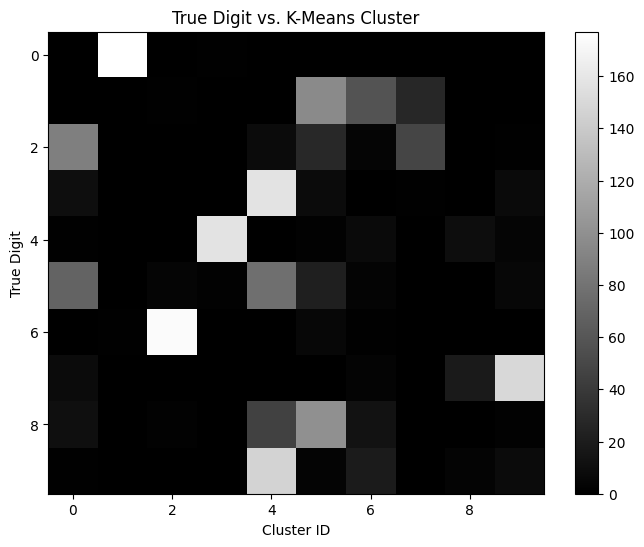

[[  0 177   0   1   0   0   0   0   0   0]
 [  0   0   1   0   0  96  58  27   0   0]
 [ 88   0   0   0   8  28   4  48   0   1]
 [ 10   0   0   0 157   8   0   1   0   7]
 [  1   0   0 158   0   2   7   0   9   4]
 [ 69   0   4   2  77  22   3   0   0   5]
 [  0   1 174   0   0   5   1   0   0   0]
 [  8   0   0   0   0   0   3   0  18 150]
 [ 11   0   2   0  46 100  13   0   0   2]
 [  1   0   0   0 146   3  19   0   3   8]]


In [14]:
# Refit a model using k=10 for a closer look at cluster composition.
analysis_model = KMeans(n_clusters=10, random_state=RANDOM_STATE, n_init=20)
analysis_clusters = analysis_model.fit_predict(X_scaled)

# Build a table showing true digit vs. assigned cluster.
cm = confusion_matrix(y, analysis_clusters)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.xlabel("Cluster ID")
plt.ylabel("True Digit")
plt.title("True Digit vs. K-Means Cluster")
plt.colorbar()
plt.show()

print(cm)


### **Task 6 — Final Analysis** [10 points]

Write a brief **200–300 word analysis** that tells the story of your clustering experiment. Your response should synthesize your results rather than simply list metric values.

Address the following:

- What structure did K-Means successfully discover?
- Which digits or writing styles were difficult to separate?
- What did you learn from comparing inertia, silhouette score, ARI, and NMI?
- What is one important limitation of applying K-Means directly to flattened image pixels?
- Suggest one reasonable next step that could improve the clustering.

$\color{orange}{\textit{Your Analysis (200–300 words):}}$

In this unsupervised clustering experiment, K-Means successfully discovered the intrinsic geometric density modes and visual prototypes of the 64-dimensional handwritten digit space without leveraging ground-truth labels during training. The algorithm cleanly isolated distinct circular and linear structures, yielding near-perfect purity in Cluster 1 (digit 0 at 99.4%) and Cluster 3 (digit 4 at 98.1%). However, K-Means struggled significantly with topologically overlapping classes and multimodal handwriting variations; rounded digits with dense upper-loop and central-junction similarities—such as 3, 5, 8, and 9—collapsed together into ambiguous mixed buckets (e.g., Cluster 4).

Comparing internal and external evaluation metrics revealed a crucial trade-off: while internal metrics like Inertia decrease monotonically and Silhouette Score reaches an optimal geometric peak at $k = 15$ ($0.1583$), label-based metrics (ARI and NMI) continued climbing monotonically to $k = 20$ ($\mathrm{ARI} = 0.6397, \mathrm{NMI} = 0.7415$). This divergence occurs because external metrics reward class purity, and splitting feature space into finer sub-clusters isolates distinct handwriting styles. A fundamental limitation of applying K-Means directly to flattened pixel vectors is its complete lack of spatial invariance; rigid Euclidean distance calculations are heavily thrown off by pixel shifts, rotations, or stroke thickness. A powerful next step to improve clustering performance would be applying a Convolutional Autoencoder or a pre-trained CNN embedding model (such as ResNet) to extract rotation-invariant, low-dimensional latent features before running K-Means.
